# Problem 1.4: fitting exponential functions to data

Exponential fit: y = f(x | A,B) = A * exp(B*x)

Logarithmic: log(y) = log(A) + B*x; used to estimate Values a = log(A) and B, due to possible numerical imprecision

Afterwards: y = exp(a + Bx)

In [14]:
import numpy as np
import numpy.linalg as la
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('dataMETR202606.csv')
# print(df)

xs = np.array(df['day'])
ys = np.array(df['avg'])

## Task 1.4.1

In [16]:
def f(x, a, B):
    return np.exp(a) * np.exp(B*x)

X = np.vstack([np.ones_like(xs), xs])

+     log(y) = a + Bx
+     0      = a + Bx - log(y)
+            = Xw - log(y) ; mit w = [a, B].T und X = [1, x]

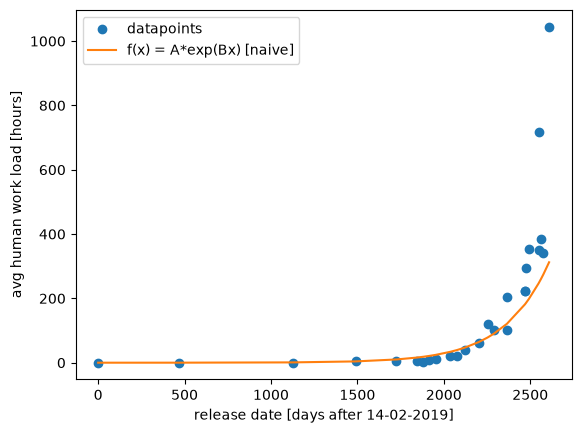

In [17]:
w = la.lstsq(X.T, np.log(ys), rcond=None)[0]

a = w[0]
B = w[1]

def plot(x, y, a, B):
    plt.figure()
    plt.plot(x, y, 'o', label='datapoints')
    plt.plot(x, f(x, a, B), label='f(x) = A*exp(Bx) [naive]')
    
    plt.xlabel('release date [days after 14-02-2019]')
    plt.ylabel('avg human work load [hours]')
    plt.legend()
    plt.show()

plot(xs, ys, a, B)


## Task 1.4.2

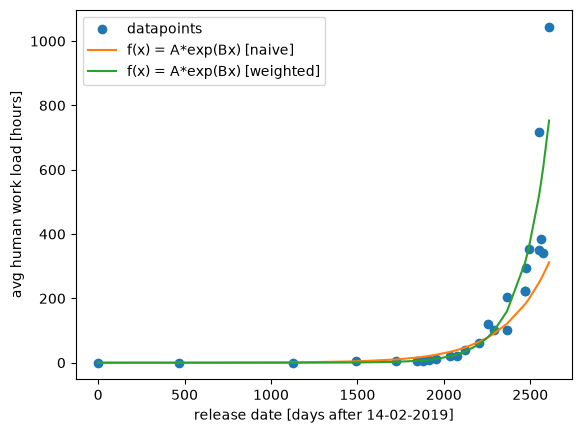

In [18]:
w_2 = la.lstsq(np.sqrt(ys)[:,None] * X.T, 
               np.sqrt(ys) * np.log(ys), rcond=None)[0]

a_2 = w_2[0]
B_2 = w_2[1]


def plot_2(x, y, a, B, a_2, B_2):
    plt.figure()
    plt.plot(x, y, 'o', label='datapoints')
    plt.plot(x, f(x, a, B), label='f(x) = A*exp(Bx) [naive]')
    plt.plot(x, f(x, a_2, B_2), label='f(x) = A*exp(Bx) [weighted]')

    plt.xlabel('release date [days after 14-02-2019]')
    plt.ylabel('avg human work load [hours]')
    plt.legend()
    plt.show()

plot_2(xs, ys, a, B, a_2, B_2)

### Comparison
+ 'lower' data points are less accurate with the weighted model (weighted is off by 1000x for first data point, and 100x for second)
+ however 'higher' datapoints are way more accurate in weighted model (off by less than 2x from middle onwards)

In [19]:
y_naive = f(xs, a, B)
y_weighted = f(xs, a_2, B_2)

comparison = pd.DataFrame({
    'model'       : df['model'],
    'y [h]'       : ys,
    'naive [h]'   : y_naive,
    'weighted [h]': y_weighted,
    # ratio prediction / data: 1.0 = perfect, 2.0 = overestimates by factor 2, 0.5 = underestimates by factor 2
    'naive / y'   : y_naive / ys,
    'weighted / y': y_weighted / ys,
})

print(comparison.to_string(index=False, float_format='{:.2f}'.format))

           model   y [h]  naive [h]  weighted [h]  naive / y  weighted / y
           GPT 2    0.05       0.01          0.00       0.23          0.00
           GPT 3    0.14       0.08          0.00       0.53          0.01
         GPT 3.5    0.60       0.97          0.06       1.63          0.10
           GPT 4    3.99       4.01          0.61       1.01          0.15
     GPT 4-Nov23    4.04      10.08          2.75       2.49          0.68
        Claude 3    3.95      16.02          5.85       4.05          1.48
     GPT 4-turbo    3.73      18.42          7.36       4.93          1.97
          GPT 4o    6.99      21.02          9.13       3.01          1.31
Claude 3.5-Jun24   11.40      24.37         11.63       2.14          1.02
      O1-preview   20.33      33.78         19.83       1.66          0.98
Claude 3.5-Oct24   20.52      39.47         25.58       1.92          1.25
      o1_inspect   38.83      46.83         33.83       1.21          0.87
      Claude 3.7   60.39 